# Comparing the supplied shear maps with the released DES Y3 covariance

**Thanks to Rafael Gomes for supplying the maps and analysis files, and to
Mike Jarvis and the TreeCorr contributors for the pair-counting code.**
This is the executable companion to
[covariance_comparison.pdf](covariance_comparison.pdf). It reproduces the
file audit, four-bin covariance comparison, direct-pair numerical check,
shear-sign check, cross-realization test and bounded pixel-variance test.
It does not run a likelihood or the full three-point estimator.

Open this notebook with `notes/covariance_comparison/` as its working
directory. By default it reads small recorded measurement tables under
`tests/covariance_map_comparison/`, plus the project's released FITS inputs.
It needs NumPy, Matplotlib, Astropy and threadpoolctl. No maps or optional
TreeCorr installation are needed to reproduce these statistical calculations.

To repeat the *measurements*, change the visible switch below. That bounded
run additionally needs the local maps, `indices_512.npy`, TreeCorr 5.1.2,
LSSTDESC.Coord 1.3.0 and astropy-healpix 1.0.3 (for NumPy 1.x).
It reads 32 primary maps, eight additional draw-one maps, and the bounded
pixel sample. It never traverses the whole simulation download.

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
import os
from pathlib import Path
import subprocess
import sys

# One worker suffices for the small matrix calculations. The optional pair
# driver explicitly sets OpenMP to three, leaving BLAS at one.
for variable in (
    "OPENBLAS_NUM_THREADS",
    "MKL_NUM_THREADS",
    "VECLIB_MAXIMUM_THREADS",
    "BLIS_NUM_THREADS",
    "OMP_NUM_THREADS",
):
    os.environ[variable] = "1"
import numpy as np
import matplotlib
from matplotlib import pyplot as plt
from astropy.io import fits
from threadpoolctl import threadpool_limits
blas_limit = threadpool_limits(limits=1, user_api="blas")
NOTE = Path.cwd()
PROJECT = NOTE.parents[1]
if not (NOTE / "covariance_comparison.tex").is_file():
    raise ValueError("Use notes/covariance_comparison as the working directory.")
MEASUREMENT = PROJECT / "tests" / "covariance_map_comparison"
RUN_MEASUREMENT = False

# This switch runs the existing, documented project driver. No new model,
# cosmology provider, or notebook-specific likelihood is constructed.
if RUN_MEASUREMENT:
    subprocess.run(
        args=[sys.executable, str(PROJECT / "scripts" / "measure_covariance_xip.py"),
              "--runs", "32"],
        cwd=PROJECT,
        check=True,
    )
    MEASUREMENT = PROJECT / "chains" / "covariance_xip_comparison"
print("Measurement source:", MEASUREMENT)

Measurement source: /Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/projects/des_3pcf/tests/covariance_map_comparison


In [2]:
# Figure style of the whole notebook: the shared plotting functions never change
# rcParams, so these lines set every font, tick and grid default.
matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
matplotlib.rcParams['mathtext.rm'] = 'Bitstream Vera Sans'
matplotlib.rcParams['mathtext.it'] = 'Bitstream Vera Sans:italic'
matplotlib.rcParams['mathtext.bf'] = 'Bitstream Vera Sans:bold'
matplotlib.rcParams['xtick.bottom'] = True
matplotlib.rcParams['xtick.top'] = False
matplotlib.rcParams['ytick.right'] = False
matplotlib.rcParams['axes.edgecolor'] = 'black'
matplotlib.rcParams['axes.linewidth'] = '1.0'
matplotlib.rcParams['axes.labelsize'] = 'medium'
matplotlib.rcParams['axes.grid'] = True
matplotlib.rcParams['grid.linewidth'] = '0.0'
matplotlib.rcParams['grid.alpha'] = '0.18'
matplotlib.rcParams['grid.color'] = 'lightgray'
matplotlib.rcParams['legend.labelspacing'] = 0.77
matplotlib.rcParams['savefig.bbox'] = 'tight'
matplotlib.rcParams['savefig.format'] = 'pdf'
matplotlib.rcParams["figure.dpi"] = 90

## 1. Use the released joint covariance as a comparison target

The project already contains Rafael's released 480-row covariance and its
paired measurements. Its rows are ordered as 200 xi-plus, 200 xi-minus, then
80 Map3 entries. The Map3 covariance block exactly matches the block in the
released Map3 measurement file. The standalone two-point covariance differs
from the joint file's two-point block; we therefore use the **joint file**
consistently for this comparison.

The joint FITS header records `NSIM=500`, while the selected upstream
analysis configuration and methods paper specify 796. These are conflicting
pieces of provenance. We record them and leave the input untouched. Do not
choose degrees of freedom for a covariance likelihood from that header
without resolving the conflict.

The released covariance is useful for checking the measurement's scale,
correlations, and row definitions. If it was estimated from the same parent
skies, agreement is **not independent validation**. Its own finite-sample
noise also remains. It cannot automatically become a noise-free reference
for the precision-expansion test.

In [3]:
from astropy.io import fits

released_data = PROJECT / "data" / "upstream_y3_observed" / "data"
joint_file = released_data / "covariance" / "xip_xim_map3_covariance_8ARCMINCUT_25Feb25.fits"
two_point_file = released_data / "dv" / "real_2pt_desy3_unblind_g2flip_matchElisa_2025Mar10.fits"
map3_file = released_data / "dv" / "real_map3_desy3_unblind_scalecut3pcf_796simcov_2025Mar11.fits"
with fits.open(name=joint_file, memmap=False) as hdus:
    released_covariance = np.array(hdus["COVMAT"].data)
    header_count = hdus["COVMAT"].header["NSIM"]
standalone_two_point = fits.getdata(filename=two_point_file, extname="COVMAT")
standalone_map3 = fits.getdata(filename=map3_file, extname="COVMAT")
print("Joint covariance shape:", released_covariance.shape)
print("FITS header NSIM:", header_count)
# Read the explicit override in the selected upstream configuration. This
# audit does not execute Cosmosis or resolve its other included parameters.
configuration = (PROJECT / "data" / "upstream_y3_observed" / "config"
                 / "unblind-metacal-796sims-february-Percival-2ptfix-3pcfsc"
                 / "unblind-metacal-shear-2pt-map3-NLA-all.ini")
configured_counts = []
for line in configuration.read_text().splitlines():
    stripped = line.strip()
    if stripped.startswith("covariance_realizations ="):
        configured_counts.append(int(stripped.split("=", 1)[1]))
assert len(configured_counts) == 1
print("Selected upstream configuration covariance_realizations:", configured_counts[0])
print("Map3 block is identical:",
      np.array_equal(released_covariance[400:, 400:], standalone_map3))
print("Standalone two-point block is identical:",
      np.array_equal(released_covariance[:400, :400], standalone_two_point))
standalone_ratio = np.diag(standalone_two_point) / np.diag(released_covariance)[:400]
print("Standalone/joint two-point variance ratio range:",
      np.min(a=standalone_ratio), np.max(a=standalone_ratio))

Joint covariance shape: (480, 480)
FITS header NSIM: 500
Selected upstream configuration covariance_realizations: 796
Map3 block is identical: True
Standalone two-point block is identical: False
Standalone/joint two-point variance ratio range: 0.8951201942964255 1.0915854485512557


## 2. Compare four actual xi-plus bins

The second measurement driver uses TreeCorr to count shear pairs in the
released angular bins for source-bin slot four. The selected joint rows are
192–195, spanning 39.622–99.527 arcminutes. Both pair-binning and shear-angle
approximation tolerances are zero. The first map also compares tree grouping
with brute-force pairs on a 2,048-pixel subset. This replaces an earlier
approximate-bin attempt whose numerical changes were too large for the
comparison.

Run the bounded measurement from Cocoa:

```bash
python projects/des_3pcf/scripts/measure_covariance_xip.py --runs 32
```

This optional driver requires TreeCorr 5.1.2, LSSTDESC.Coord 1.3.0 and
astropy-healpix. It uses three OpenMP workers, leaving one core for the map
stream, with BLAS at one. The notebook below only reads its small saved table.

TreeCorr's spherical shear basis points west/north. We use `flip_g2=True`
to implement the same east/north assumption as the coarse aperture pilot.
The first map also records the opposite sign; it does not select a preferred
convention by matching the covariance. All map pixels have equal weights,
which still needs comparison with the producer's weighting. These maps are
NSIDE 512; the methods paper describes 1024. Matching angular bin edges
therefore establishes only part of an estimator match.

For $N$ provisional parent surveys, subtract their mean and compute

$$\widehat C_{ij}=\frac{1}{N-1}\sum_s
 (d_{si}-\bar d_i)(d_{sj}-\bar d_j).$$

This estimates the fluctuations of **one survey**, which is what the
released covariance describes. Dividing it by $N$ would instead estimate
the covariance of the ensemble mean and would make the comparison wrong.

In [4]:
XIP_MEASUREMENT = MEASUREMENT
print((XIP_MEASUREMENT / "measurement.txt").read_text())
xip_table = np.loadtxt(fname=XIP_MEASUREMENT / "xip.txt", ndmin=2)
xip_rows = np.loadtxt(fname=XIP_MEASUREMENT / "rows.txt", ndmin=2)
# Only the declared east/north assumption enters the sample covariance.
# The alternate sign for the first map is a convention check, not a new sky.
xip_sample = xip_table[xip_table[:, 1] == 1., 2:]
xip_parents = xip_table[xip_table[:, 1] == 1., 0].astype(int)
assert np.unique(xip_parents).size == len(xip_parents)
indices = xip_rows[:, 0].astype(int)
np.testing.assert_array_equal(indices, np.arange(192, 196))
xip_reference = released_covariance[np.ix_(indices, indices)]
# Rows are surveys and columns are angular bins. Subtract each column's
# mean; residuals.T @ residuals sums the outer products of all surveys.
# Dividing by N-1 gives the covariance of ONE survey, not of its mean.
xip_mean = np.mean(a=xip_sample, axis=0)
residuals = xip_sample - xip_mean
xip_covariance = residuals.T @ residuals / (len(xip_sample) - 1)
np.testing.assert_allclose(
    xip_covariance,
    np.cov(m=xip_sample, rowvar=False, ddof=1),
    rtol=1.e-13,
    atol=0.,
)
variance_ratio = np.diag(xip_covariance) / np.diag(xip_reference)
xip_mean = np.mean(a=xip_sample, axis=0)
mean_standard_error = np.sqrt(np.diag(xip_covariance) / len(xip_sample))
print("Measured primary run labels:", xip_parents)
print("Mean xi-plus:", xip_mean)
print("Standard error of that mean:", mean_standard_error)
print("One-survey variance / released variance:", variance_ratio)
# Correlation differences remain in the matrix; the diagonal ratio alone
# cannot establish equality of the two covariance matrices.
xip_factor = np.linalg.cholesky(xip_reference)
# If C_ref = L L^T, solve on the left and then on the right to form
# L^-1 C_sample L^-T. Triangular solves avoid explicitly forming L^-1.
left_solved = np.linalg.solve(a=xip_factor, b=xip_covariance)
xip_whitened = np.linalg.solve(a=xip_factor, b=left_solved.T).T
print("Covariance eigenvalues in released-model units:",
      np.linalg.eigvalsh(xip_whitened))
for flip in (0, 1):
    check = np.loadtxt(fname=XIP_MEASUREMENT / f"tree_check_flip{flip}.txt")
    print("Sign check", flip, "max tree/brute xi difference:",
          np.max(a=np.abs(check[:, 0] - check[:, 1])))

Parents: 32
Cut: 0
Draw: 0
Source-bin slot: 4
TreeCorr version: 5.1.2
OpenMP: 3
BLAS: 1
Weights: equal per retained pixel; producer weights unavailable
Tree approximations: bin_slop=0 angle_slop=0; 2048-pixel tree/brute check
Metric: Arc
NSIDE: 512
Pixel ordering: RING inferred from footprint
Signs: first map both signs; main sample flip_g2=True (assumed east/north)
Bins: released xi-plus rows 192..195, 39.622..99.527 arcmin
No catalogue-noise covariance from TreeCorr is used
Released matrix may share parent simulations; this is a consistency check
Cross tests: 8 same-run draw pairs and disjoint different-run pairs
Elapsed seconds: 502.265

Measured primary run labels: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31]
Mean xi-plus: [7.16869147e-06 5.79657858e-06 4.43694802e-06 3.05194156e-06]
Standard error of that mean: [1.96757673e-07 1.86474479e-07 1.48359059e-07 1.05140586e-07]
One-survey variance / released variance: [1.40577469 1.8

The bars below measure sensitivity to leaving out one parent at a time.
They describe uncertainty in our small measured sample; they omit noise in
the released reference and any dependence from shared parent skies. The
line at one marks equal variances for a single survey. A disagreement calls
for checks of resolution, weights, shear conventions, and simulation
content before interpreting it as a failure of covariance physics.

Even agreement would establish consistency for four two-point rows only.
The Map3 and cross-covariance blocks still require the published triangle
measurement and scale cuts. No precision correction or Fisher constraint is
computed from this comparison.

If $r_i^{(-s)}$ is the ratio after removing run $s$, first average those
leave-one-out ratios to obtain $\bar r_i^{\rm jack}$. Their scatter gives

$$\widehat{\mathrm{Var}}_{\rm jack}(r_i)=\frac{N-1}{N}
\sum_s(r_i^{(-s)}-\bar r_i^{\rm jack})^2.$$

The plotted bar is the square root of this quantity. Each leave-one-out
sample shares almost all its maps with the others; the prefactor accounts
for that reuse in the jackknife estimate. It is not the ordinary variance
of 32 independent estimates.

Variance-ratio jackknife standard errors: [0.3723697  0.42048988 0.44524493 0.28075769]


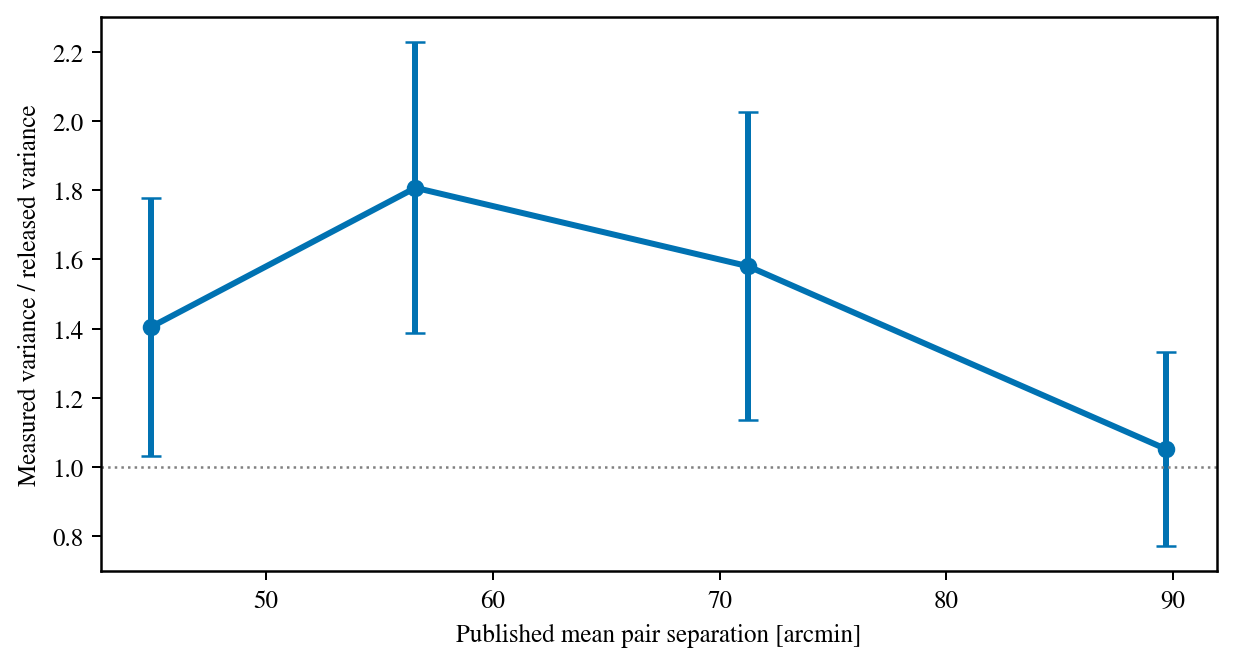

In [5]:
# These small jackknife calculations reuse the measured vectors only.
leave_one_out = []
for omitted in range(len(xip_sample)):
    selection = np.arange(len(xip_sample)) != omitted
    covariance = np.cov(m=xip_sample[selection], rowvar=False, ddof=1)
    leave_one_out.append(np.diag(covariance) / np.diag(xip_reference))
leave_one_out = np.asarray(leave_one_out)
centered = leave_one_out - np.mean(a=leave_one_out, axis=0)
count = len(xip_sample)
ratio_standard_error = np.sqrt((count - 1.) / count * np.sum(a=centered**2, axis=0))
print("Variance-ratio jackknife standard errors:", ratio_standard_error)
fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(x=xip_rows[:, 3], y=variance_ratio, yerr=ratio_standard_error,
            color="#0072B2", marker="o", linewidth=2.4, capsize=4)
ax.axhline(y=1., color="0.5", linestyle=":", linewidth=1.)
ax.set_xlabel("Published mean pair separation [arcmin]")
ax.set_ylabel("Measured variance / released variance")
plt.show()

## 3. Record the numerical and shear-convention checks separately

The tree/direct-pair test compares the *same* 2,048 pixels with the same
spin-two convention. Agreement tests the pair-counting calculation. It does
not identify which convention the map producer intended. The first primary
map was measured with both signs of its second shear component; the following
cell reports that difference in units of the released single-survey error.
A small difference is not permission to leave the convention undefined.
The pair driver uses zero angular-bin and shear-angle approximation tolerances;
none of TreeCorr's estimated shot-noise errors enters our covariance.

Two additional controls check the cross-correlation route itself. Cross-correlating
two distinct catalogue objects containing the *same map* must recover its
auto-correlation. A second check compares the cross-correlation of two
*different maps* with direct pair enumeration on the same 2,048-pixel subset.
Together they test normalization and pair processing before interpreting
an observed cross signal near zero.

In [6]:
# Both rows refer to the SAME sky: they must never count as two surveys.
first_run = xip_table[:, 0] == 0
sign_rows = xip_table[first_run]
assert np.array_equal(sign_rows[:, 1], np.array([0., 1.]))
sign_difference = sign_rows[1, 2:] - sign_rows[0, 2:]
released_errors = np.sqrt(np.diag(xip_reference))
print("Changing flip_g2, difference / released single-survey error:",
      sign_difference / released_errors)
for flip in (0, 1):
    check = np.loadtxt(fname=MEASUREMENT / f"tree_check_flip{flip}.txt")
    assert np.all(check[:, 2] > 0)
    np.testing.assert_allclose(check[:, 0], check[:, 1], rtol=0., atol=1.e-16)
    print("Sign", flip, "direct-pair subset check passed; pair counts:", check[:, 2])
# This positive control must retain a signal: distinct catalogue objects
# carrying identical shear fields should give the usual auto-correlation.
for filename in ("self_cross_check.txt", "cross_tree_check.txt"):
    check = np.loadtxt(fname=MEASUREMENT / filename)
    np.testing.assert_allclose(check[:, 0], check[:, 1], rtol=0., atol=1.e-16)
    print(filename, "maximum difference:", np.max(a=np.abs(check[:, 0] - check[:, 1])))

Changing flip_g2, difference / released single-survey error: [-0.03151488 -0.0382525   0.01814052  0.02726496]
Sign 0 direct-pair subset check passed; pair counts: [ 336.  510.  830. 1346.]
Sign 1 direct-pair subset check passed; pair counts: [ 336.  510.  830. 1346.]
self_cross_check.txt maximum difference: 1.929541053845296e-18
cross_tree_check.txt maximum difference: 0.0


## 4. Does changing the realization label preserve the shear signal?

A correlation between *different* noise draws can answer a question that
pixel variance alone cannot. Suppose the two maps contain the same sky
signal, $s$, and independent noise fields:

$$g^{(0)}=s+n^{(0)}.$$

The second map is

$$g^{(1)}=s+n^{(1)}.$$

For this explanation, read the following product as either scalar component
of the properly rotated shear pair. Expand it before taking an average:

$$g^{(0)}_i g^{(1)}_j
=s_i s_j+s_i n^{(1)}_j+n^{(0)}_i s_j+n^{(0)}_i n^{(1)}_j.$$

If each noise field has conditional mean zero and the two fields are
independent at fixed sky, the last three terms have zero expectation. The
cross-correlation therefore retains the shared sky signal:

$$\mathbb{E}[g^{(0)}_i g^{(1)}_j\mid s]=s_i s_j.$$

At nonzero separation, the same-map correlation also estimates that signal
if the within-map noise has no correlation between distinct pixels. This
last condition must be stated: correlated noise can survive a same-map
measurement. A comparison between different independent skies has zero
ensemble expectation, provided their mean shear is zero.

The driver tests eight same-run pairs (draw zero against draw one), with
runs 0–7. Its control pairs those runs with runs 8–15, using draw zero in
both. All pairs use the same four exact angular bins and source-bin slot
four. This is a bounded diagnostic, not a replacement for the producer's
metadata. The four angular points are correlated; do not interpret them as
four independent detections. Error bars below are standard errors across
eight pairs, conditional on the run labels identifying independent skies.

Paired run labels: [0 1 2 3 4 5 6 7]
Same-run cross minus auto, in units of 1e-6: [-6.83031104 -5.62317479 -4.14217592 -3.30359751]
Standard error of that paired difference, in units of 1e-6: [0.48189759 0.39811453 0.33378138 0.27577426]
Same map mean in units of 1e-6: [6.66017328 5.73154053 4.08204228 3.22477877]
Same map standard error in units of 1e-6: [0.34129513 0.40175141 0.23916788 0.18752039]
Different draw, same run mean in units of 1e-6: [-0.17013776  0.10836574 -0.06013363 -0.07881873]
Different draw, same run standard error in units of 1e-6: [0.26141942 0.23175443 0.24913458 0.16806279]
Different run mean in units of 1e-6: [ 0.27151875 -0.10032067  0.20725485 -0.08756649]
Different run standard error in units of 1e-6: [0.16336948 0.30818003 0.16998511 0.18933952]


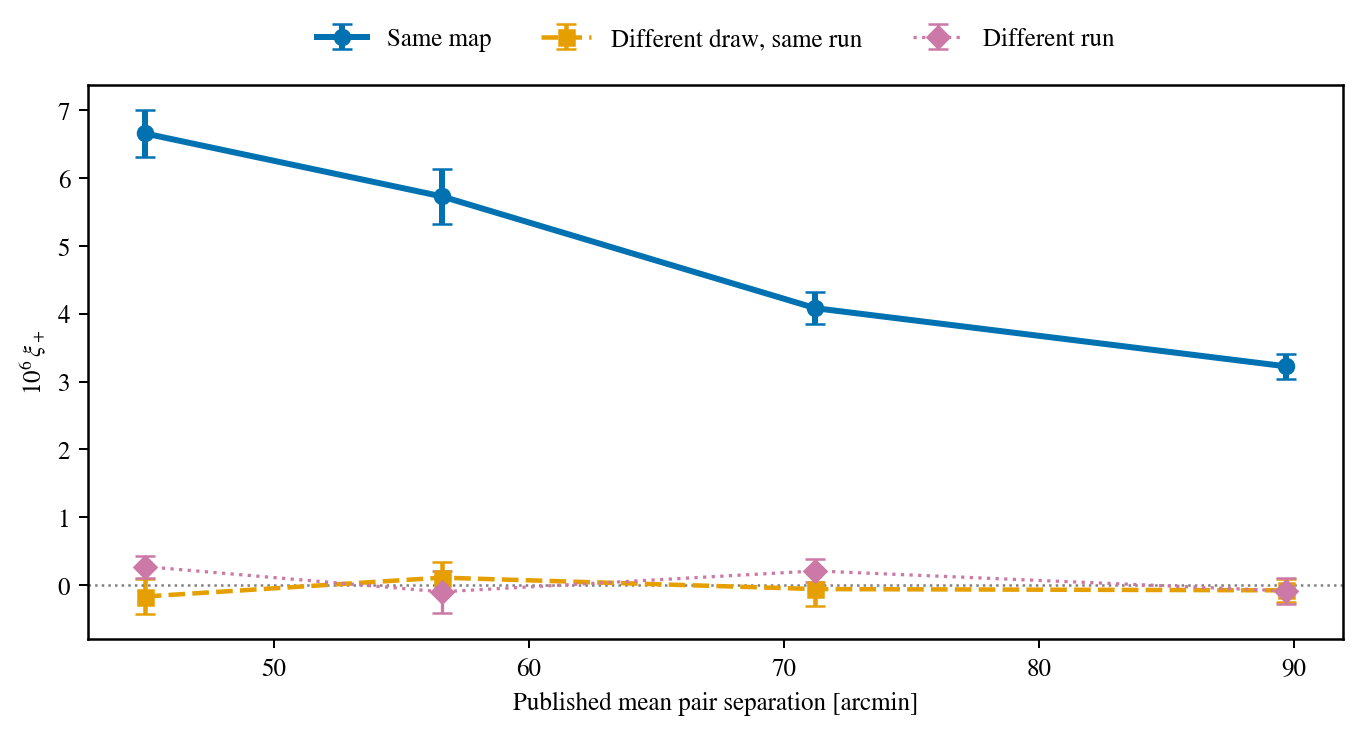

In [7]:
# Each row identifies both maps before listing the four cross-correlations.
# The first two columns let us separate same-run tests from different-run
# controls without inferring their meanings from row order.
cross_table = np.loadtxt(fname=XIP_MEASUREMENT / "cross_xip.txt", ndmin=2)
same_selection = cross_table[:, 0] == cross_table[:, 1]
same_cross = cross_table[same_selection, 3:]
different_cross = cross_table[~same_selection, 3:]
paired_runs = cross_table[same_selection, 0].astype(int)
assert len(np.unique(paired_runs)) == len(paired_runs)
auto_selection = np.isin(element=xip_parents, test_elements=paired_runs)
auto_pairs = xip_sample[auto_selection]
np.testing.assert_array_equal(xip_parents[auto_selection], paired_runs)
assert same_cross.shape == different_cross.shape == auto_pairs.shape

# Compare the SAME primary runs in the auto and within-run curves. This
# removes the unnecessary variation from choosing a different sky sample.
# The different-run control still has finite fluctuations about zero.
paired_difference = same_cross - auto_pairs
print("Paired run labels:", paired_runs)
print("Same-run cross minus auto, in units of 1e-6:",
      1.e6 * np.mean(a=paired_difference, axis=0))
print("Standard error of that paired difference, in units of 1e-6:",
      1.e6 * np.std(a=paired_difference, axis=0, ddof=1) / np.sqrt(len(paired_runs)))
fig, ax = plt.subplots(figsize=(9, 4))
for sample, name, color, marker, width, style in (
    (auto_pairs, "Same map", "#0072B2", "o", 2.4, "-"),
    (same_cross, "Different draw, same run", "#E69F00", "s", 1.8, "--"),
    (different_cross, "Different run", "#CC79A7", "D", 1.3, ":"),
):
    mean = np.mean(a=sample, axis=0)
    standard_error = np.std(a=sample, axis=0, ddof=1) / np.sqrt(len(sample))
    print(name, "mean in units of 1e-6:", 1.e6 * mean)
    print(name, "standard error in units of 1e-6:", 1.e6 * standard_error)
    ax.errorbar(
        x=xip_rows[:, 3],
        y=1.e6 * mean,
        yerr=1.e6 * standard_error,
        color=color,
        marker=marker,
        linewidth=width,
        linestyle=style,
        capsize=4,
        label=name,
    )
ax.axhline(y=0., color="0.5", linestyle=":", linewidth=1.)
ax.set_xlabel("Published mean pair separation [arcmin]")
ax.set_ylabel(r"$10^6\,\xi_+$")
legend = ax.legend(
    loc="lower center",
    bbox_to_anchor=(0.5, 1.02),
    ncol=3,
    frameon=False,
)
fig.canvas.draw()
assert legend.get_window_extent().y0 > ax.get_window_extent().y1
plt.show()

The eight same-run cross-correlations are consistent with zero at these
angles, while the same-map correlations are clearly positive. The paired
cross-minus-auto difference is much larger than its sampling uncertainty.
Under the assumptions just derived, changing `nreal` does **not** behave as
changing only independent pixel noise on one fixed, aligned sky.

This does not identify what was randomized. For example, changing or rotating
the sky can erase a shared correlation at fixed coordinates, while correlated
noise could contribute to the same-map signal. The zero different-run control
also does not prove statistical independence of the full parent simulations.
We retain the labels and ask for the generating procedure before assigning
physical names to covariance components or counting independent skies.

## 5. Why the earlier pixel-variance test was less decisive

For a fixed common pixel signal and independent zero-mean noise, the spatial
variance of one map contains both contributions:

$$V_{\rm one}=V_s+V_n.$$

Averaging $K$ noise draws keeps the signal and reduces the noise variance:

$$V_{\rm mean}=V_s+V_n/K.$$

Multiply the second equation by $K$ and subtract the first. The noise cancels:

$$K V_{\rm mean}-V_{\rm one}=(K-1)V_s.$$

This gives a diagnostic estimate of a shared spatial variance:

$$\widehat V_s=\frac{K V_{\rm mean}-V_{\rm one}}{K-1}.$$

The following calculation uses 8,192 common pixel positions, twenty draws and
two runs. Spatially correlated pixels are not 8,192 independent measurements.
A small result alone would not establish that a weak sky signal is absent;
that is why we also measured the angular cross-correlations above.

In [8]:
# The recorded table contains the TWO primitive variances, so the algebra
# is recomputed here rather than loading only a final shared-fraction number.
# With RUN_MEASUREMENT enabled, this bounded loop replaces the recorded table
# using actual maps. It reads neither all pixels nor all runs into memory.
if RUN_MEASUREMENT:
    pixel_rows = []
    pixels = np.linspace(0, 369190 - 1, 8192, dtype=int)
    for run in (0, 1):
        pixel_sum = np.zeros(shape=(4, 2, len(pixels)))
        variance_sum = np.zeros(shape=(4, 2))
        for draw in range(20):
            name = f"ShearMaps_DESY3_run_{run:04d}_ncut0_nreal{draw}.npy"
            mapped = np.load(
                file=PROJECT / "maps_cov_512_v2" / name,
                mmap_mode="r",
                allow_pickle=False,
            )
            sample = np.array(mapped[:, :, pixels])
            del mapped
            pixel_sum += sample
            variance_sum += np.var(a=sample, axis=2)
        one_variance = variance_sum / 20.
        mean_variance = np.var(a=pixel_sum / 20., axis=2)
        for source in range(4):
            for component in range(2):
                pixel_rows.append([run, source, component, 20,
                                   one_variance[source, component],
                                   mean_variance[source, component]])
    pixel_table = np.asarray(pixel_rows)
    np.savetxt(
        fname=MEASUREMENT / "pixel_variance.txt",
        X=pixel_table,
        header="run source_slot component K mean_one_map_variance variance_of_mean_map",
    )
else:
    pixel_table = np.loadtxt(fname=MEASUREMENT / "pixel_variance.txt")
K = pixel_table[:, 3]
one_variance = pixel_table[:, 4]
mean_variance = pixel_table[:, 5]
shared_variance = (K * mean_variance - one_variance) / (K - 1.)
for run in (0, 1):
    selected = pixel_table[:, 0] == run
    fraction = shared_variance[selected] / one_variance[selected]
    print("Run", run, "shared spatial fraction in percent:")
    print(100. * fraction.reshape(4, 2))
# A noisy estimate can be negative. We retain it instead of clipping it,
# because clipping would introduce a positive bias and hide the uncertainty.

Run 0 shared spatial fraction in percent:
[[-0.08229554 -0.01795086]
 [ 0.06016794  0.08981536]
 [-0.00435602  0.0387818 ]
 [ 0.06566693 -0.02310817]]
Run 1 shared spatial fraction in percent:
[[-0.05975481  0.17200806]
 [ 0.19487395 -0.04915119]
 [ 0.32193086  0.32100318]
 [ 0.29779421  0.25644622]]


## 6. What can be concluded, and what must be supplied next?

The map and released variances have similar scales, but the four-dimensional
covariances are not established to be equal. Exact pair checks control the
numerical estimator; they do not fix missing weights, the NSIDE difference,
or the unconfirmed shear convention. The same-run cross test challenges our
initial interpretation of `nreal` as noise-only randomization.

For the next comparison we need the map-generation definition of `run`,
`ncut` and `nreal`; the noise and shear conventions; catalogue/pixel weights;
and the lineage connecting these 512 maps to the released covariance and its
500-versus-796 simulation counts. A shared origin would make this a useful
processing consistency test. Independent validation of a precision correction
would still require separate parent skies and a matched analytic model.

The notebook does not modify a reference covariance, fit a rescaling, clip
negative eigenvalues, or infer independent-sky counts from filenames. Its
statistical calculations and figures are reproducible from the recorded
small tables. The bounded measurement can be repeated using the explicit
switch at the top.